# penguin species

In [1]:
import seaborn as sns
import pandas as pd
data = sns.load_dataset('penguins')
df = pd.DataFrame(data)
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [2]:
print(f"Table Shape: {df.shape}")
print(" ")
print(f"Columns: {df.columns}")
print(" ")
print(f"types: {df.dtypes}")

Table Shape: (344, 7)
 
Columns: Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')
 
types: species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


In [3]:


print(pd.DataFrame(df.isna().sum()))
print(" ")

print(" ")
print(pd.DataFrame(df.count()))

                    0
species             0
island              0
bill_length_mm      2
bill_depth_mm       2
flipper_length_mm   2
body_mass_g         2
sex                11
 
 
                     0
species            344
island             344
bill_length_mm     342
bill_depth_mm      342
flipper_length_mm  342
body_mass_g        342
sex                333


In [4]:
print(df.value_counts("species"))

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [5]:
X = df[["island","bill_length_mm","bill_depth_mm","flipper_length_mm", "body_mass_g", "sex" ]]
y = df["species"]

print(X.head())
print(" ")
print(y.head())

      island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
0  Torgersen            39.1           18.7              181.0       3750.0   
1  Torgersen            39.5           17.4              186.0       3800.0   
2  Torgersen            40.3           18.0              195.0       3250.0   
3  Torgersen             NaN            NaN                NaN          NaN   
4  Torgersen            36.7           19.3              193.0       3450.0   

      sex  
0    Male  
1  Female  
2  Female  
3     NaN  
4  Female  
 
0    Adelie
1    Adelie
2    Adelie
3    Adelie
4    Adelie
Name: species, dtype: object


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(275, 6) (69, 6)


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier

numeric_features = ["bill_length_mm","bill_depth_mm","flipper_length_mm", "body_mass_g", ]
category_features =["island", "sex"]


numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="mean")),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ('encoder', OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numeric_features),
    ("cat", categorical_pipeline, category_features)

    ])


pipe_tree = Pipeline(
    [("preprocessor", preprocessor), ("classifier", DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, min_samples_split=2, random_state=42))]
)
pipe_knn = Pipeline(

     [("preprocessor", clone(preprocessor)), ("classifier", KNeighborsClassifier())]
 )

pipe_tree.fit(X_train, y_train)
result_tree = pipe_tree.predict(X_test)

print(" ")

pipe_knn.fit(X_train,y_train)
result_knn = pipe_knn.predict(X_test)




print("Tree train:", pipe_tree.score(X_train, y_train), "test:", pipe_tree.score(X_test, y_test))
print(" ")
print("KNN train:", pipe_knn.score(X_train, y_train), "test:", pipe_knn.score(X_test, y_test))

 
Tree train: 1.0 test: 0.9855072463768116
 
KNN train: 0.9963636363636363 test: 0.9855072463768116


 **Confusion Matrix and cross validation **

[[29  0  1]
 [ 0 14  0]
 [ 0  0 25]]


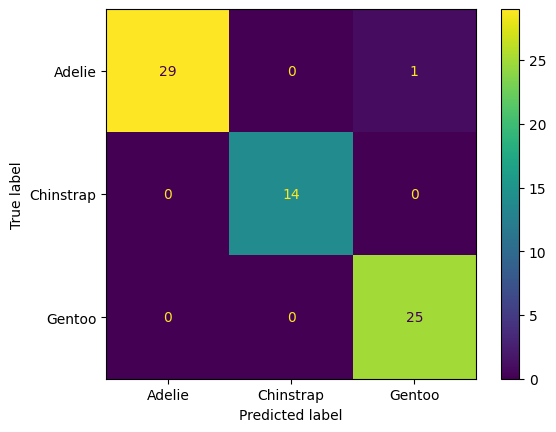

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


mat_tree = confusion_matrix(y_test,result_tree, labels=pipe_tree.classes_)
print(mat_tree)

disp = ConfusionMatrixDisplay(mat_tree, display_labels=pipe_tree.classes_)


disp.plot()

plt.show()





[[29  1  0]
 [ 0 14  0]
 [ 0  0 25]]


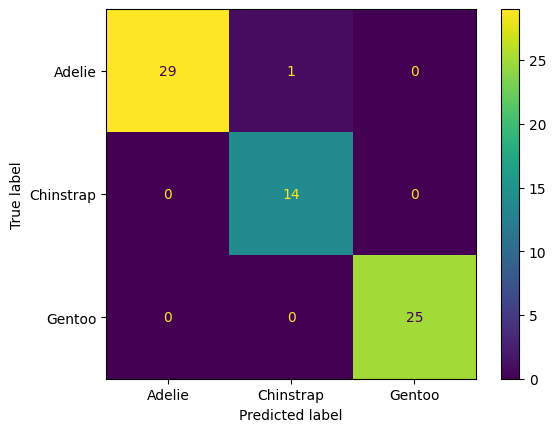

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


mat_knn = confusion_matrix(y_test,result_knn, labels=pipe_tree.classes_)
print(mat_knn)

disp = ConfusionMatrixDisplay(mat_knn, display_labels=pipe_knn.classes_)


disp.plot()

plt.show()


In [10]:
from sklearn.model_selection import cross_val_score



validate_tree = cross_val_score(pipe_tree, X_train, y_train, cv=5)
val_knn = cross_val_score(pipe_knn, X_train, y_train, cv=5)

print(validate_tree)
print(val_knn)
print(val_knn.mean().round(3), "±", val_knn.std().round(3))
print(validate_tree.mean().round(3), "±", validate_tree.std().round(3))


[0.94545455 0.94545455 0.96363636 0.94545455 0.98181818]
[1.         0.98181818 1.         0.98181818 0.96363636]
0.985 ± 0.014
0.956 ± 0.015



## Conclusion

- **Both models classified 68 of 69 test penguins correctly** (test accuracy 0.986).
- **Cross-validation decided the winner:** KNN scored 0.985 ± 0.014, the decision tree 0.956 ± 0.015. KNN generalises better.
- **The decision tree overfits a little:** it scores 1.000 on the training data but only 0.956 in cross-validation. KNN's train score (0.996) is much closer to its CV score.
- **Both mistakes were unusual Adelie penguins:** the tree called a very large Adelie (flipper 210 mm) a Gentoo, and KNN called a long-billed Adelie from Dream island a Chinstrap. Models fail on the edge cases, not on typical penguins.
- **Next steps:** tune KNN's number of neighbours (k) with GridSearchCV, and try a Random Forest.